<a href="https://colab.research.google.com/github/madhu12-c/amazon-prime-eda/blob/main/Amazon_Prime_Video_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project Name    - Amazon Prime TV Shows and Movies Analysis (EDA)

##### Project Type    - EDA
##### Contribution    - Individual
##### Team Member 1 - Madhusudan Jitendra Chanda

# Project Summary -

This project presents a complete Exploratory Data Analysis (EDA) of the Amazon Prime Video catalogue available in the United States. The goal is to study the platform's content library and turn raw data into clear, business-relevant insights that can guide content strategy, marketing and investment decisions in the highly competitive streaming industry.

The analysis uses two datasets. The first, titles.csv, contains 9,871 unique movies and TV shows described by 15 attributes such as type (movie or show), release year, runtime, genres, production countries, age certification, and ratings from IMDb and TMDB. The second, credits.csv, contains 124,235 records of the cast and crew (actors and directors) associated with each title. The two tables are connected through a common title id, forming a one-to-many relationship in which one title is linked to many people.

The project follows a structured workflow. First, the data is understood through its shape, structure, data types, duplicate rows and missing values, and a missing-value heatmap is used to visually locate gaps. We found that several columns are only partially populated: seasons is empty for all movies (which is expected, since movies have no seasons), age_certification is missing for roughly two-thirds of titles, and the rating columns (imdb_score, tmdb_score, imdb_votes) are missing for titles that have little or no online presence. Recognising that not all missing values represent errors was a key part of the cleaning strategy.

In the data wrangling stage, exact duplicate rows are removed, structurally missing season values are filled with zero for movies, missing categories are labelled as "Unknown", and the genres and production_countries columns - which are stored as text that looks like Python lists - are parsed into real lists so individual genres and countries can be counted accurately. This parsing step is essential for several of the most informative charts.

The visual analysis is organised using the UBM framework. Univariate analysis studies one variable at a time, such as the split between movies and shows, the distribution of IMDb scores and runtimes, the most common genres, and the leading production countries. Bivariate analysis examines relationships between two variables, for example how ratings differ between movies and shows, how IMDb scores relate to the number of votes, and how average ratings have changed over the years. Multivariate analysis, including a correlation heatmap and a pair plot, studies several numerical variables together to reveal deeper patterns. In total, more than twenty charts are produced using a variety of chart types.

The analysis reveals several meaningful patterns. Amazon Prime's catalogue is heavily dominated by movies rather than shows, content volume has grown sharply in recent years, drama and comedy are the most common genres, and the United States is by far the largest producer of titles. Ratings are concentrated in a middle band, and the number of votes a title receives is closely linked to its popularity. Each chart is accompanied by a short explanation of why the chart was chosen, what insight it reveals, and how that insight could create a positive or negative business impact.

The findings are useful to several stakeholders. Content strategists can see which genres and formats dominate and where gaps exist; marketing teams can identify popular genres and highly rated titles to promote; and investors can understand production trends, regional concentration and overall content quality. The project concludes with clear, data-driven recommendations and notes possible future extensions such as deeper text analysis of descriptions, predictive modelling of ratings, and building an interactive dashboard.

# GitHub Link -

https://github.com/madhu12-c/amazon-prime-eda


# Problem Statement


In today's competitive streaming industry, platforms like Amazon Prime Video constantly expand their content libraries to serve diverse audiences. With thousands of titles available, data-driven insights are essential for understanding what the platform offers and how its catalogue has evolved.

This dataset was created to list all shows and movies available on Amazon Prime Video (United States) so that the catalogue can be analysed to uncover useful facts. Through this analysis we aim to answer key questions:

1. Content Diversity - Which genres and categories dominate the platform, and are movies more common than TV shows?
2. Regional Availability - How is content distributed across different production countries?
3. Trends Over Time - How has Amazon Prime's content library grown across release years?
4. IMDb Ratings & Popularity - Which titles are the highest-rated or most popular, and how do ratings behave across the catalogue?

By analysing this data, businesses, content creators and analysts can uncover trends that influence subscription growth, user engagement and content investment strategy.

#### Define Your Business Objective?

The business objective is to analyse the Amazon Prime Video catalogue and convert it into actionable insights that help the platform make smarter content strategy, marketing and investment decisions - identifying which content types, genres, regions and quality levels dominate the library, where the gaps and opportunities lie, and how these patterns can support subscriber growth and stronger audience engagement.

# Hypotheses & Assumptions

**Assumptions**
1. The dataset is a snapshot of the US Amazon Prime catalogue - findings describe the US library, not other regions.
2. `release_year` is the original release year of the title, not the date it was added to Prime.
3. Missing `seasons` means the title is a movie (structural gap), not an error.
4. The first item in `genres` / `production_countries` is treated as the title's *main* genre/country.
5. IMDb/TMDB scores are a fair proxy for audience-perceived quality; votes/popularity are a proxy for reach.

**Hypotheses to check**
- **H1:** TV shows are rated higher on IMDb than movies.
- **H2:** IMDb score and TMDB score are positively correlated (both platforms agree on quality).
- **H3:** Average IMDb score differs significantly across genres.
- **H4:** The catalogue has grown strongly in recent decades (visual check - Chart 2 & 19).
- **H5:** Content production is concentrated in a few countries, mainly the US (visual check - Chart 7).

H1-H3 are tested statistically after the charts; H4-H5 are answered by the visualisations.

# General Guidelines : -  

1.   Well-structured, formatted, and commented code is required.
2.   Exception Handling, Production Grade Code & Deployment Ready Code will be a plus. Those students will be awarded some additional credits.
     
     The additional credits will have advantages over other students during Star Student selection.
       
             [ Note: - Deployment Ready Code is defined as, the whole .ipynb notebook should be executable in one go
                       without a single error logged. ]

3.   Each and every logic should have proper comments.
4. You may add as many number of charts you want. Make Sure for each and every chart the following format should be answered.
        


# Chart visualization code

            

*   Why did you pick the specific chart?
*   What is/are the insight(s) found from the chart?
* Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

5. You have to create at least 20 logical & meaningful charts having important insights.


[ Hints : - Do the Vizualization in  a structured way while following "UBM" Rule.

U - Univariate Analysis,

B - Bivariate Analysis (Numerical - Categorical, Numerical - Numerical, Categorical - Categorical)

M - Multivariate Analysis
 ]





# *Let's Begin !*

## *1. Know Your Data*

### Import Libraries

In [35]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
%matplotlib inline
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (8, 5)
pd.set_option('display.max_columns', None)

### Dataset Loading

In [36]:
# Load both CSV files. In Google Colab, upload titles.csv and credits.csv
# using the Files panel (left sidebar) before running this cell.
def load_csv(path):
    try:
        data = pd.read_csv(path)
        print(f'Loaded {path}: {data.shape[0]:,} rows x {data.shape[1]} columns')
        return data
    except FileNotFoundError:
        raise FileNotFoundError(f'{path} not found - upload it to the Colab session first.')

titles = load_csv('titles.csv')
credits = load_csv('credits.csv')

Loaded titles.csv: 9,871 rows x 15 columns
Loaded credits.csv: 124,235 rows x 5 columns


### Dataset First View

In [37]:
print('TITLES dataset - first 5 rows:')
display(titles.head())

print('CREDITS dataset - first 5 rows:')
display(credits.head())

TITLES dataset - first 5 rows:


,id,title,type,description,release_year,age_certification,runtime,genres,production_countries,seasons,imdb_id,imdb_score,imdb_votes,tmdb_popularity,tmdb_score
0,ts20945,The Three Stooges,SHOW,The Three Stooges were an American vaudeville ...,1934,TV-PG,19,"['comedy', 'family', 'animation', 'action', 'f...",['US'],26.0,tt0850645,8.6,1092.0,15.424,7.6
1,tm19248,The General,MOVIE,"During America’s Civil War, Union spies steal ...",1926,NaN,78,"['action', 'drama', 'war', 'western', 'comedy'...",['US'],NaN,tt0017925,8.2,89766.0,8.647,8.0
2,tm82253,The Best Years of Our Lives,MOVIE,It's the hope that sustains the spirit of ever...,1946,NaN,171,"['romance', 'war', 'drama']",['US'],NaN,tt0036868,8.1,63026.0,8.435,7.8
3,tm83884,His Girl Friday,MOVIE,"Hildy, the journalist former wife of newspaper...",1940,NaN,92,"['comedy', 'drama', 'romance']",['US'],NaN,tt0032599,7.8,57835.0,11.270,7.4
4,tm56584,In a Lonely Place,MOVIE,An aspiring actress begins to suspect that her...,1950,NaN,94,"['thriller', 'drama', 'romance']",['US'],NaN,tt0042593,7.9,30924.0,8.273,7.6


CREDITS dataset - first 5 rows:


,person_id,id,name,character,role
0,59401,ts20945,Joe Besser,Joe,ACTOR
1,31460,ts20945,Moe Howard,Moe,ACTOR
2,31461,ts20945,Larry Fine,Larry,ACTOR
3,21174,tm19248,Buster Keaton,Johnny Gray,ACTOR
4,28713,tm19248,Marion Mack,Annabelle Lee,ACTOR


### Dataset Rows & Columns count

In [38]:
print('Titles  dataset -> Rows:', titles.shape[0], '| Columns:', titles.shape[1])
print('Credits dataset -> Rows:', credits.shape[0], '| Columns:', credits.shape[1])

Titles  dataset -> Rows: 9871 | Columns: 15
Credits dataset -> Rows: 124235 | Columns: 5


### Dataset Information

In [39]:
titles.info()
print()
credits.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9871 entries, 0 to 9870
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id                    9871 non-null   object 
 1   title                 9871 non-null   object 
 2   type                  9871 non-null   object 
 3   description           9752 non-null   object 
 4   release_year          9871 non-null   int64  
 5   age_certification     3384 non-null   object 
 6   runtime               9871 non-null   int64  
 7   genres                9871 non-null   object 
 8   production_countries  9871 non-null   object 
 9   seasons               1357 non-null   float64
 10  imdb_id               9204 non-null   object 
 11  imdb_score            8850 non-null   float64
 12  imdb_votes            8840 non-null   float64
 13  tmdb_popularity       9324 non-null   float64
 14  tmdb_score            7789 non-null   float64
dtypes: float64(5), int64(

#### Duplicate Values

In [40]:
print('Duplicate rows in titles :', titles.duplicated().sum())
print('Duplicate rows in credits:', credits.duplicated().sum())

Duplicate rows in titles : 3
Duplicate rows in credits: 56


#### Missing Values/Null Values

In [41]:
print('Missing values in TITLES:')
print(titles.isnull().sum())

print('\nMissing values in CREDITS:')
print(credits.isnull().sum())

Missing values in TITLES:
id                         0
title                      0
type                       0
description              119
release_year               0
age_certification       6487
runtime                    0
genres                     0
production_countries       0
seasons                 8514
imdb_id                  667
imdb_score              1021
imdb_votes              1031
tmdb_popularity          547
tmdb_score              2082
dtype: int64

Missing values in CREDITS:
person_id        0
id               0
name             0
character    16287
role             0
dtype: int64


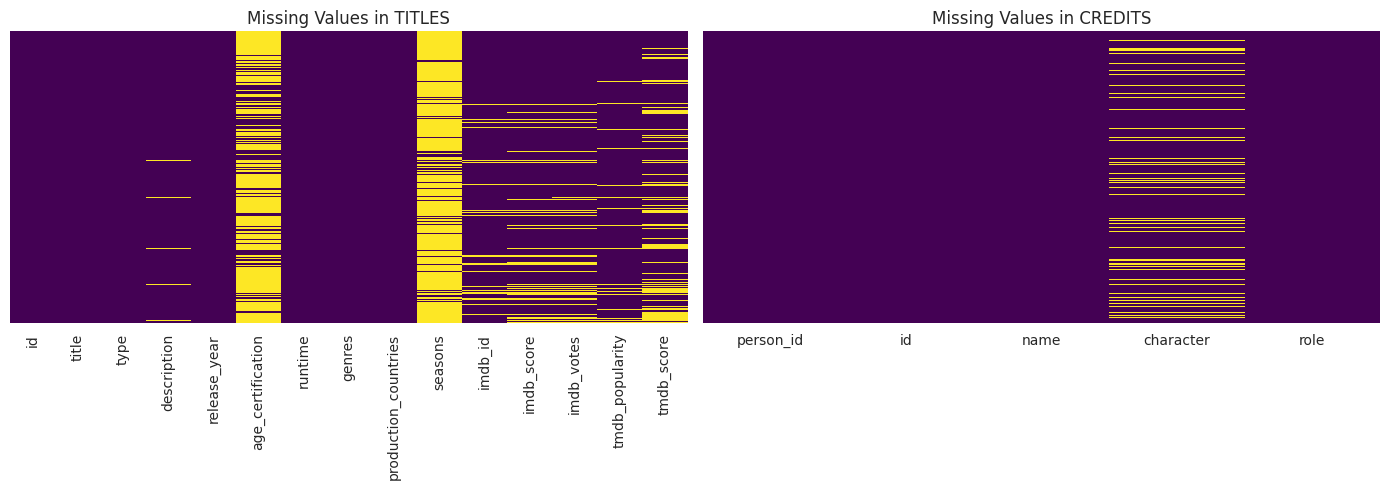

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(titles.isnull(), cbar=False, yticklabels=False, cmap='viridis', ax=axes[0])
axes[0].set_title('Missing Values in TITLES')
sns.heatmap(credits.isnull(), cbar=False, yticklabels=False, cmap='viridis', ax=axes[1])
axes[1].set_title('Missing Values in CREDITS')
plt.tight_layout()
plt.show()

### What did you know about your dataset?

The dataset is made of two linked tables:

- titles - 9,871 rows and 15 columns. Each row is one movie or show, with details like type, release year, runtime, genres, production countries, age certification and IMDb/TMDB ratings.
- credits - 124,235 rows and 5 columns. Each row is one person (actor or director) connected to a title. The two tables share the id column, so one title links to many people (a one-to-many relationship).

Duplicates: 3 duplicate rows in titles and 56 in credits - these will be removed during data wrangling.

Missing values are present and meaningful:
- seasons is missing for ~8,500 rows because movies do not have seasons (only shows do) - this is *structural*, not an error.
- age_certification is missing for about two-thirds of titles (many titles are simply unrated).
- The rating columns (imdb_score, imdb_votes, tmdb_score, tmdb_popularity) are missing for titles with little or no online presence.
- In credits, character is missing mainly for directors (who play no character).

So the data is fairly rich but needs cleaning before analysis - particularly handling the missing values sensibly and parsing the genres and production_countries text into real lists.

## *2. Understanding Your Variables*

In [43]:
print('Titles columns :', list(titles.columns))
print('\nCredits columns:', list(credits.columns))

Titles columns : ['id', 'title', 'type', 'description', 'release_year', 'age_certification', 'runtime', 'genres', 'production_countries', 'seasons', 'imdb_id', 'imdb_score', 'imdb_votes', 'tmdb_popularity', 'tmdb_score']

Credits columns: ['person_id', 'id', 'name', 'character', 'role']


In [44]:
display(titles.describe())
display(titles.describe(include='all'))

,release_year,runtime,seasons,imdb_score,imdb_votes,tmdb_popularity,tmdb_score
count,9871.000000,9871.000000,1357.000000,8850.000000,8.840000e+03,9324.000000,7789.000000
mean,2001.327221,85.973052,2.791452,5.976395,8.533614e+03,6.910204,5.984247
std,25.810071,33.512466,4.148958,1.343842,4.592015e+04,30.004098,1.517986
min,1912.000000,1.000000,1.000000,1.100000,5.000000e+00,0.000011,0.800000
25%,1995.500000,65.000000,1.000000,5.100000,1.170000e+02,1.232000,5.100000
50%,2014.000000,89.000000,1.000000,6.100000,4.625000e+02,2.536000,6.000000
75%,2018.000000,102.000000,3.000000,6.900000,2.236250e+03,5.634000,6.900000
max,2022.000000,549.000000,51.000000,9.900000,1.133692e+06,1437.906000,10.000000


,id,title,type,description,release_year,age_certification,runtime,genres,production_countries,seasons,imdb_id,imdb_score,imdb_votes,tmdb_popularity,tmdb_score
count,9871,9871,9871,9752,9871.000000,3384,9871.000000,9871,9871,1357.000000,9204,8850.000000,8.840000e+03,9324.000000,7789.000000
unique,9868,9737,2,9734,NaN,11,NaN,2028,497,NaN,9201,NaN,NaN,NaN,NaN
top,tm89134,The Lost World,MOVIE,No overview found.,NaN,R,NaN,['drama'],['US'],NaN,tt0033683,NaN,NaN,NaN,NaN
freq,2,3,8514,5,NaN,1249,NaN,908,4810,NaN,2,NaN,NaN,NaN,NaN
mean,NaN,NaN,NaN,NaN,2001.327221,NaN,85.973052,NaN,NaN,2.791452,NaN,5.976395,8.533614e+03,6.910204,5.984247
std,NaN,NaN,NaN,NaN,25.810071,NaN,33.512466,NaN,NaN,4.148958,NaN,1.343842,4.592015e+04,30.004098,1.517986
min,NaN,NaN,NaN,NaN,1912.000000,NaN,1.000000,NaN,NaN,1.000000,NaN,1.100000,5.000000e+00,0.000011,0.800000
25%,NaN,NaN,NaN,NaN,1995.500000,NaN,65.000000,NaN,NaN,1.000000,NaN,5.100000,1.170000e+02,1.232000,5.100000
50%,NaN,NaN,NaN,NaN,2014.000000,NaN,89.000000,NaN,NaN,1.000000,NaN,6.100000,4.625000e+02,2.536000,6.000000
75%,NaN,NaN,NaN,NaN,2018.000000,NaN,102.000000,NaN,NaN,3.000000,NaN,6.900000,2.236250e+03,5.634000,6.900000


### Variables Description

Here is what each column in the titles data means. id is a unique title id that also links to the credits table. title is the name of the movie or show, and type tells us whether it is a MOVIE or a SHOW. description is a short summary, release_year is the year it came out, and runtime is the length in minutes. age_certification is the maturity rating like PG-13 or R, and it is missing for a lot of titles. genres and production_countries are stored as list-like text. seasons only applies to shows. The remaining columns are quality signals: imdb_id, imdb_score and imdb_votes come from IMDb, while tmdb_popularity and tmdb_score come from TMDB.

In the credits data, person_id identifies a person, id is the title they worked on, name is the actor or director, character is the role they played, and role says whether they were an ACTOR or a DIRECTOR.

### Check Unique Values for each variable.

In [45]:
for col in titles.columns:
    print(f'{col:22s}: {titles[col].nunique():>6} unique values')

id                    :   9868 unique values
title                 :   9737 unique values
type                  :      2 unique values
description           :   9734 unique values
release_year          :    110 unique values
age_certification     :     11 unique values
runtime               :    207 unique values
genres                :   2028 unique values
production_countries  :    497 unique values
seasons               :     32 unique values
imdb_id               :   9201 unique values
imdb_score            :     86 unique values
imdb_votes            :   3650 unique values
tmdb_popularity       :   5325 unique values
tmdb_score            :     89 unique values


## 3. *Data Wrangling*

### Data Wrangling Code

In [46]:
import ast

df = titles.copy()
df = df.drop_duplicates().reset_index(drop=True)

# movies have no seasons, so fill those gaps with 0
df['seasons'] = df['seasons'].fillna(0)
df['age_certification'] = df['age_certification'].fillna('Unknown')

# turn the genre / country text into real python lists
def parse_list(value):
    try:
        result = ast.literal_eval(value)
        return result if isinstance(result, list) else []
    except (ValueError, SyntaxError):
        return []

df['genres_list'] = df['genres'].apply(parse_list)
df['countries_list'] = df['production_countries'].apply(parse_list)

df['main_genre'] = df['genres_list'].apply(lambda x: x[0] if len(x) > 0 else 'Unknown')
df['main_country'] = df['countries_list'].apply(lambda x: x[0] if len(x) > 0 else 'Unknown')
df['decade'] = (df['release_year'] // 10) * 10

credits_clean = credits.drop_duplicates().reset_index(drop=True)

print('Cleaned titles shape :', df.shape)
print('Cleaned credits shape:', credits_clean.shape)
df.head(3)

Cleaned titles shape : (9868, 20)
Cleaned credits shape: (124179, 5)


,id,title,type,description,release_year,age_certification,runtime,genres,production_countries,seasons,imdb_id,imdb_score,imdb_votes,tmdb_popularity,tmdb_score,genres_list,countries_list,main_genre,main_country,decade
0,ts20945,The Three Stooges,SHOW,The Three Stooges were an American vaudeville ...,1934,TV-PG,19,"['comedy', 'family', 'animation', 'action', 'f...",['US'],26.0,tt0850645,8.6,1092.0,15.424,7.6,"[comedy, family, animation, action, fantasy, h...",[US],comedy,US,1930
1,tm19248,The General,MOVIE,"During America’s Civil War, Union spies steal ...",1926,Unknown,78,"['action', 'drama', 'war', 'western', 'comedy'...",['US'],0.0,tt0017925,8.2,89766.0,8.647,8.0,"[action, drama, war, western, comedy, european]",[US],action,US,1920
2,tm82253,The Best Years of Our Lives,MOVIE,It's the hope that sustains the spirit of ever...,1946,Unknown,171,"['romance', 'war', 'drama']",['US'],0.0,tt0036868,8.1,63026.0,8.435,7.8,"[romance, war, drama]",[US],romance,US,1940


### Outlier Check

runtime          outliers:   275 | min: 1.00 | max: 549.00
imdb_score       outliers:    65 | min: 1.10 | max: 9.90
imdb_votes       outliers:  1354 | min: 5.00 | max: 1,133,692.00
tmdb_popularity  outliers:   916 | min: 0.00 | max: 1,437.91


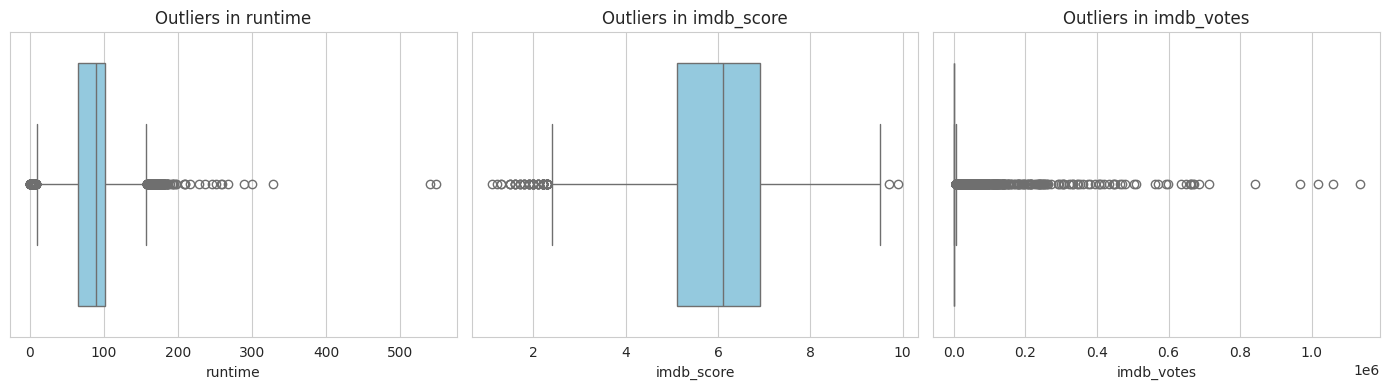

In [47]:
def count_iqr_outliers(series):
    # IQR rule: values below Q1 - 1.5*IQR or above Q3 + 1.5*IQR are flagged as outliers
    s = series.dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    mask = (s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)
    return mask.sum(), s.min(), s.max()

for col in ['runtime', 'imdb_score', 'imdb_votes', 'tmdb_popularity']:
    n_out, lo, hi = count_iqr_outliers(df[col])
    print(f'{col:16s} outliers: {n_out:5d} | min: {lo:,.2f} | max: {hi:,.2f}')

# boxplots to see the outliers visually
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ['runtime', 'imdb_score', 'imdb_votes']):
    sns.boxplot(x=df[col], ax=ax, color='skyblue')
    ax.set_title(f'Outliers in {col}')
plt.tight_layout()
plt.show()

**Decision on outliers:** I checked them with the IQR rule but did **not** delete them. They are real values, not data-entry errors:
- Very long runtimes are genuine (multi-part films, concert recordings, long episodes) and very short ones are shorts/trailers-style titles.
- Huge `imdb_votes` / `tmdb_popularity` values are the platform's blockbusters - removing them would remove the most important titles.
- Low/high IMDb scores (like 1.1 or 9.9) are valid ratings.

Instead of removing them, I handle them in the charts: a log scale for votes, and medians/boxplots (which are not pulled by extreme values) where averages could mislead.

### What all manipulations have you done and insights you found?

Manipulations performed:

1. Removed duplicate rows - 3 from titles and 56 from credits - so counts are not inflated.
2. seasons - filled the missing values with 0, because they are missing only for movies (which genuinely have no seasons). This is a *structural* gap, not a data error.
3. age_certification - filled missing values with the label "Unknown", keeping those rows for analysis instead of deleting two-thirds of the data.
4. Parsed genres and production_countries from list-like text (e.g. "['comedy','drama']") into real Python lists (genres_list, countries_list). This is the key step that lets us count individual genres and countries accurately.
5. Created helper columns - main_genre, main_country (the primary genre/country of each title) and decade (release year grouped into 10-year buckets) to support the charts.

Note on rating columns: imdb_score, imdb_votes, tmdb_score and tmdb_popularity still contain some missing values. We intentionally did not fill these with fake numbers, because inventing ratings would distort the analysis. Instead, each rating-based chart simply drops the missing values for that chart only (using .dropna()), so we never lose data in the other columns.

Insights from wrangling: most titles are concentrated in a few genres and in the United States, and a large share of titles are movies rather than shows - patterns we will confirm visually in the next section.

## *4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables*

#### Chart - 1 - Movies vs TV Shows (Univariate)

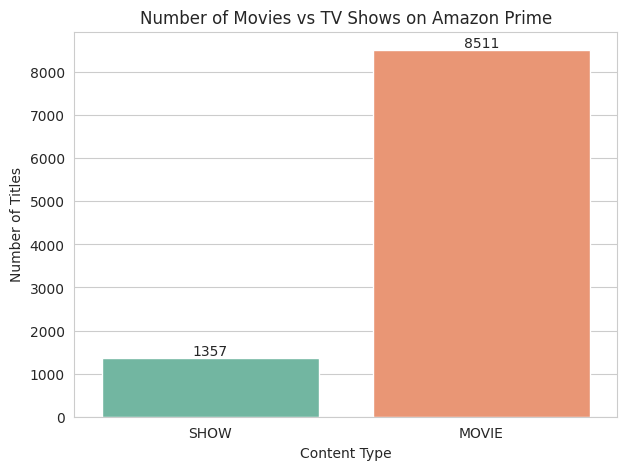

In [48]:
plt.figure(figsize=(7, 5))
ax = sns.countplot(data=df, x='type', hue='type', palette='Set2', legend=False)
plt.title('Number of Movies vs TV Shows on Amazon Prime')
plt.xlabel('Content Type')
plt.ylabel('Number of Titles')
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width()/2, p.get_height()), ha='center', va='bottom')
plt.show()

##### 1. Why did you pick the specific chart?

A countplot is the simplest and clearest way to compare the frequency of a single categorical variable with only two values (Movie vs Show). The bar heights make the size difference immediately obvious.

##### 2. What is/are the insight(s) found from the chart?

The catalogue is heavily skewed toward movies: about 8,511 movies vs only 1,357 TV shows - roughly 86% movies and 14% shows. Amazon Prime is far more of a movie library than a series library.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive impact: a large movie library is a strong selling point for subscribers who mainly want films, and it gives marketing plenty of titles to promote.

Possible negative impact: TV shows usually drive *long-term engagement and retention* (viewers binge season after season). The very small share of shows is a risk - subscribers may churn to competitors with stronger original series. This suggests Prime should invest more in TV-show content to balance the catalogue.

#### Chart - 2 - Titles Released per Year (Univariate)

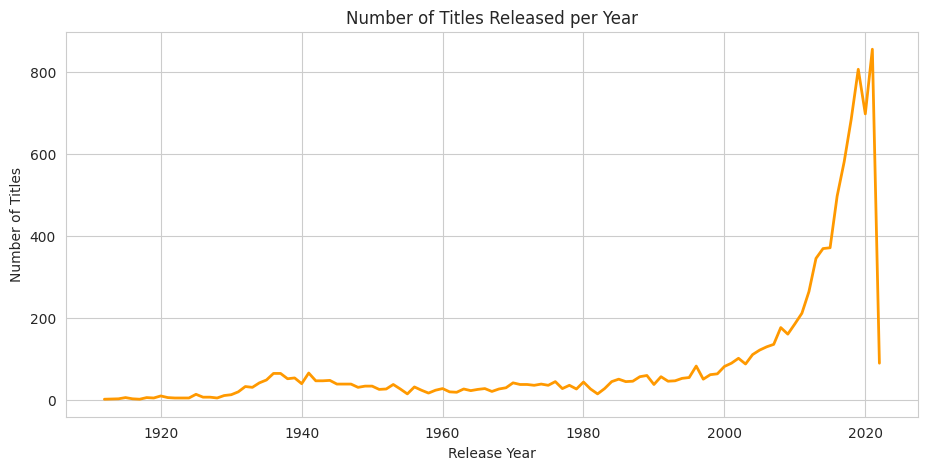

In [49]:
titles_per_year = df['release_year'].value_counts().sort_index()
plt.figure(figsize=(11, 5))
plt.plot(titles_per_year.index, titles_per_year.values, color='#FF9900', linewidth=2)
plt.title('Number of Titles Released per Year')
plt.xlabel('Release Year')
plt.ylabel('Number of Titles')
plt.show()

##### 1. Why did you pick the specific chart?

A line chart is the best choice for showing how a quantity changes over time. The continuous line makes the growth trend of the catalogue across release years easy to follow.

##### 2. What is/are the insight(s) found from the chart?

Titles span from 1912 to 2022, but the volume is tiny for most of the 20th century and then rises sharply after about 2010. The peak is around 2021 (856 titles), followed by 2019 and 2020. The overwhelming majority of the catalogue is recent content.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive impact: the steep recent growth shows Amazon Prime has aggressively expanded its library, keeping the platform fresh with new releases - attractive to subscribers who want current content.

Possible negative impact: such heavy reliance on very recent titles means the platform's appeal depends on maintaining a high rate of new additions. A slowdown in new content (as the small dip after 2021 hints) could reduce perceived value. A small drop in the final year may also be due to incomplete data for the most recent year.

#### Chart - 3 - Distribution of IMDb Scores (Univariate)

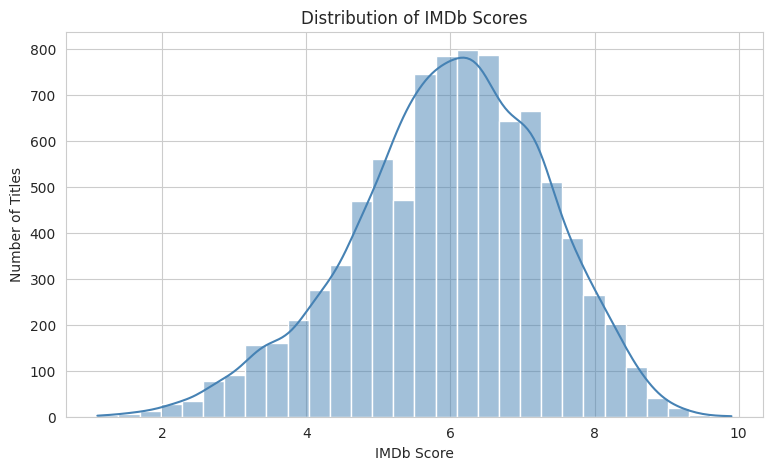

In [50]:
plt.figure(figsize=(9, 5))
sns.histplot(df['imdb_score'].dropna(), bins=30, kde=True, color='steelblue')
plt.title('Distribution of IMDb Scores')
plt.xlabel('IMDb Score')
plt.ylabel('Number of Titles')
plt.show()

##### 1. Why did you pick the specific chart?

A histogram with a KDE curve is ideal for seeing the shape of a single numeric variable - where ratings cluster, how spread out they are, and whether the distribution is skewed.

##### 2. What is/are the insight(s) found from the chart?

IMDb scores are roughly bell-shaped and centred around 6.0 (mean ~ 5.98, median ~ 6.1), ranging from 1.1 to 9.9. Most titles are average-to-decent; very few are rated above 8 or below 3. The catalogue is dominated by middling-quality content rather than critically acclaimed titles.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive impact: a large body of average-rated content still provides volume and variety, which supports a "something for everyone" library.

Possible negative impact: the scarcity of high-rated (8+) titles is a concern, because top-rated "prestige" content is what attracts new subscribers and earns awards/press. Relying on average content can weaken the platform's premium image. Prime should curate and acquire more high-quality titles.

#### Chart - 4 - Distribution of Runtime (Univariate)

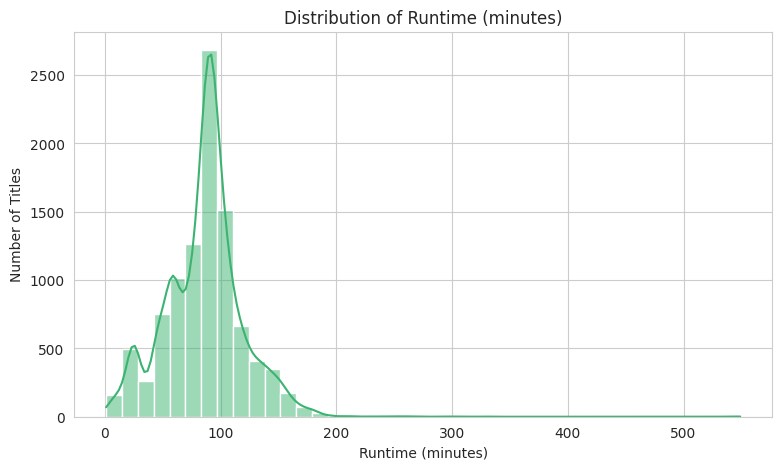

In [51]:
plt.figure(figsize=(9, 5))
sns.histplot(df['runtime'], bins=40, kde=True, color='mediumseagreen')
plt.title('Distribution of Runtime (minutes)')
plt.xlabel('Runtime (minutes)')
plt.ylabel('Number of Titles')
plt.show()

##### 1. Why did you pick the specific chart?

A histogram shows how the length of titles is distributed and reveals the typical runtime as well as any unusual very-short or very-long values (outliers).

##### 2. What is/are the insight(s) found from the chart?

Runtime centres around 86-89 minutes (mean ~ 86, median ~ 89), the typical length of a feature film. There is a secondary cluster at very short runtimes (a few minutes), which corresponds to TV-show episodes and short films, and a long tail of titles running well over two hours.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive impact: the strong concentration around standard feature-film length confirms the catalogue is built around familiar, easy-to-consume movie formats that audiences expect.

Possible negative impact: the very short runtimes can distort averages and may represent episodes or filler content; if too much of the library is very short, it could feel less substantial to subscribers looking for full-length films and series. These short-runtime entries should be reviewed separately.

#### Chart - 5 - Age Certification Distribution (Univariate)

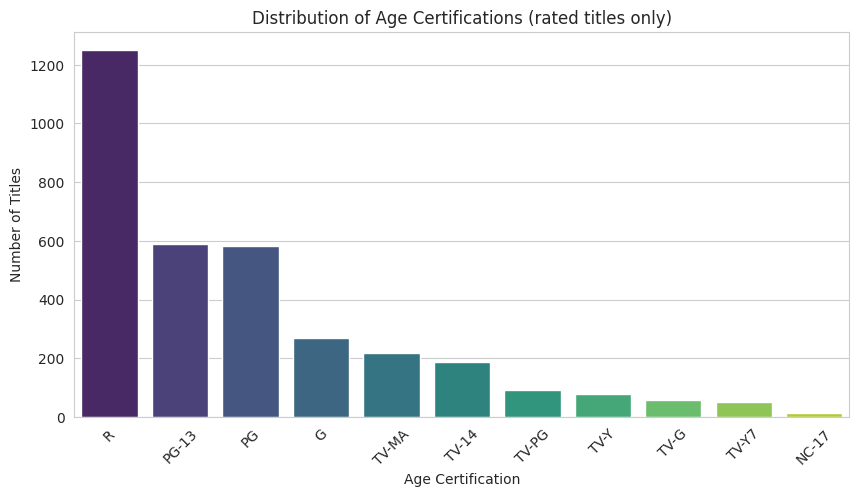

In [52]:
cert_counts = df[df['age_certification'] != 'Unknown']['age_certification'].value_counts()
plt.figure(figsize=(10, 5))
sns.barplot(x=cert_counts.index, y=cert_counts.values, hue=cert_counts.index, palette='viridis', legend=False)
plt.title('Distribution of Age Certifications (rated titles only)')
plt.xlabel('Age Certification')
plt.ylabel('Number of Titles')
plt.xticks(rotation=45)
plt.show()

##### 1. Why did you pick the specific chart?

A bar chart is well suited to comparing the counts of several categories (the different certification labels) and ranking them from most to least common.

##### 2. What is/are the insight(s) found from the chart?

Among rated titles, R (1,249) is the most common, followed by PG-13 (588) and PG (582). Mature/teen ratings dominate over family-friendly (G, TV-Y) ratings. Importantly, about two-thirds of all titles have no certification at all ("Unknown"), so most of the catalogue is unrated.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive impact: a strong supply of mature (R, PG-13) content serves the large adult audience, which is a major streaming demographic.

Possible negative impact: the relatively small amount of clearly family-rated (G, TV-Y) content may limit appeal to families with young children - a valuable, loyal segment. Also, the huge share of unrated titles makes parental filtering harder and can hurt trust. Prime could add certifications and expand family content.

#### Chart - 6 - Top 10 Genres (Univariate)

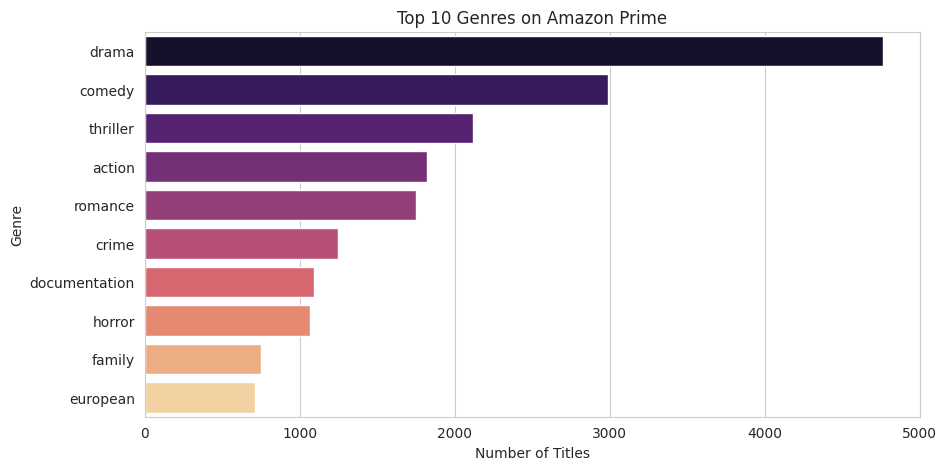

In [53]:
genre_counts = df.explode('genres_list')['genres_list'].value_counts().head(10)
plt.figure(figsize=(10, 5))
sns.barplot(x=genre_counts.values, y=genre_counts.index, hue=genre_counts.index, palette='magma', legend=False)
plt.title('Top 10 Genres on Amazon Prime')
plt.xlabel('Number of Titles')
plt.ylabel('Genre')
plt.show()

##### 1. Why did you pick the specific chart?

A horizontal bar chart ranks the genres clearly and keeps the genre names readable. Because a title can belong to multiple genres, exploding the list first ensures every genre is counted correctly.

##### 2. What is/are the insight(s) found from the chart?

Drama (4,762) and Comedy (2,987) are by far the most common genres, followed by Thriller (2,119), Action (1,820) and Romance (1,751). Documentation, crime, horror and family appear further down. The catalogue is built mainly around drama and comedy.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive impact: drama and comedy have the widest audience appeal, so a deep library in these genres satisfies the largest share of viewers and is easy to market.

Possible negative impact: over-concentration in a few genres means niche audiences (e.g. sci-fi, documentary, horror fans) are under-served and may look elsewhere. Heavy genre overlap can also make the catalogue feel repetitive. Prime could diversify into under-represented genres to capture new segments.

#### Chart - 7 - Top 10 Production Countries (Univariate)

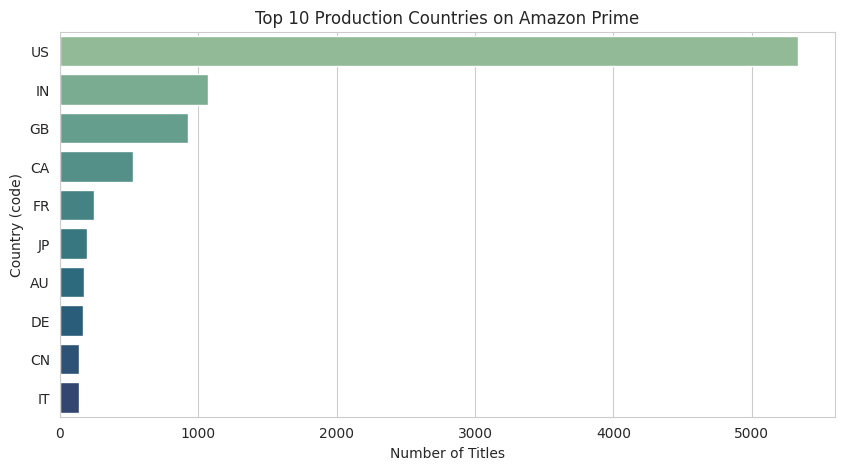

In [54]:
country_counts = df.explode('countries_list')['countries_list'].value_counts().head(10)
plt.figure(figsize=(10, 5))
sns.barplot(x=country_counts.values, y=country_counts.index, hue=country_counts.index, palette='crest', legend=False)
plt.title('Top 10 Production Countries on Amazon Prime')
plt.xlabel('Number of Titles')
plt.ylabel('Country (code)')
plt.show()

##### 1. Why did you pick the specific chart?

A horizontal bar chart ranks the producing countries by number of titles, making it easy to see how concentrated or spread out content production is across regions.

##### 2. What is/are the insight(s) found from the chart?

The United States (5,331) produces the most titles by a wide margin, followed by India (1,072) and the United Kingdom (928), then Canada and France. Content production is heavily concentrated in the US, but India's strong second place shows a significant non-Western presence.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive impact: a strong US library suits Prime's largest English-speaking markets, while India's high ranking positions Prime well in one of the fastest-growing streaming markets in the world - a real growth opportunity.

Possible negative impact: the heavy US concentration means many other large regions (Europe beyond the UK/France, Latin America, East Asia) are under-represented. This limits local-language appeal and can slow international subscriber growth. Investing in more regional/local content would broaden Prime's global reach.

#### Chart - 8 - IMDb Score by Content Type (Bivariate: Numerical-Categorical)

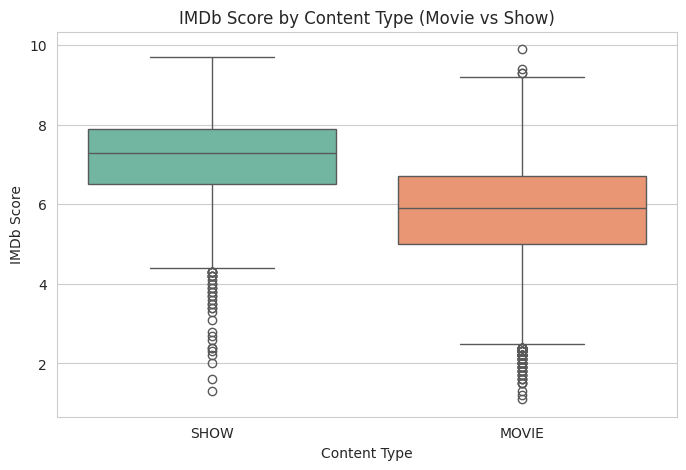

In [55]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='type', y='imdb_score', hue='type', palette='Set2', legend=False)
plt.title('IMDb Score by Content Type (Movie vs Show)')
plt.xlabel('Content Type')
plt.ylabel('IMDb Score')
plt.show()

##### 1. Why did you pick the specific chart?

A box plot is the standard way to compare a numeric variable across categories. It shows the median, spread (interquartile range) and outliers for each group side by side, making differences between movies and shows easy to see.

##### 2. What is/are the insight(s) found from the chart?

TV shows are rated noticeably higher than movies. Shows average about 7.1 on IMDb while movies average about 5.8, and the show box sits clearly higher with a tighter spread. Despite being only 14% of the catalogue, shows are the higher-quality content.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive impact: this is a strong, actionable insight - shows deliver higher ratings *and* drive bingeing/retention. Investing more in TV shows could raise the catalogue's overall perceived quality.

Possible negative impact: the current heavy tilt toward lower-rated movies may be dragging down the platform's average quality and viewer satisfaction. Continuing to add many average movies while neglecting high-rated shows is a strategic risk that could weaken Prime against series-focused rivals.

#### Chart - 9 - Runtime by Content Type (Bivariate: Numerical-Categorical)

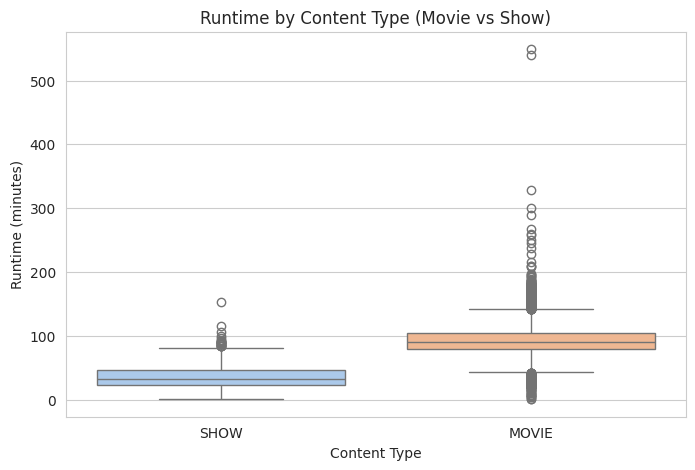

In [56]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='type', y='runtime', hue='type', palette='pastel', legend=False)
plt.title('Runtime by Content Type (Movie vs Show)')
plt.xlabel('Content Type')
plt.ylabel('Runtime (minutes)')
plt.show()

##### 1. Why did you pick the specific chart?

A box plot again lets us compare the runtime distribution of movies versus shows directly, including how different their typical lengths and outliers are.

##### 2. What is/are the insight(s) found from the chart?

Movies and shows have very different runtimes. Movies have a median of ~91 minutes, while shows have a median of ~33 minutes (because the runtime is per episode). Movies also show a long upper tail of very long films, whereas shows are tightly clustered at short per-episode lengths.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive impact: the clear runtime difference confirms the two formats serve different viewing needs - long-form films for a full sitting, short episodes for quick or repeat viewing. Offering both supports varied watch occasions.

Possible negative impact: the very short show runtimes mean the runtime column cannot be compared fairly across types without separating them; mixing them could mislead analysis (and recommendation systems). It also confirms most "long-form" value comes from movies, reinforcing the earlier concern about the thin show library.

#### Chart - 10 - IMDb Score vs Number of Votes (Bivariate: Numerical-Numerical)

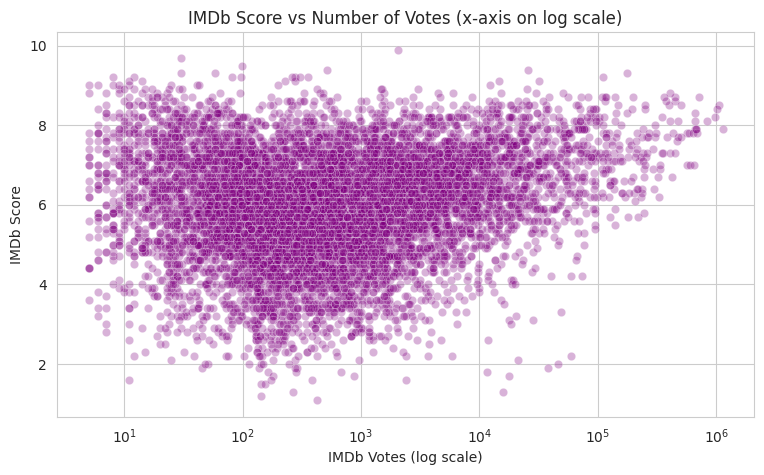

In [57]:
plt.figure(figsize=(9, 5))
sns.scatterplot(data=df, x='imdb_votes', y='imdb_score', alpha=0.3, color='purple')
plt.xscale('log')
plt.title('IMDb Score vs Number of Votes (x-axis on log scale)')
plt.xlabel('IMDb Votes (log scale)')
plt.ylabel('IMDb Score')
plt.show()

##### 1. Why did you pick the specific chart?

A scatter plot is the right tool for showing the relationship between two numeric variables. The log scale is used because vote counts range from a handful to hundreds of thousands, which would otherwise squash most points against the axis.

##### 2. What is/are the insight(s) found from the chart?

There is only a weak positive relationship (correlation ~ 0.17). Titles with very few votes span the whole score range (1-10), but as the number of votes grows, scores tend to settle into the middle-to-high band (around 6-8). In other words, widely-watched titles are rarely terrible, but a high score does not require many votes.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive impact: popular (high-vote) titles being rarely low-rated means Prime's most-watched content is generally safe quality - good for promotion and recommendations.

Possible negative impact: because score and popularity are only weakly linked, a high rating alone does not guarantee a large audience. Many highly-rated but low-vote "hidden gems" may be going unnoticed - a missed engagement opportunity that better discovery/recommendation could fix.

#### Chart - 11 - Average IMDb Score by Decade (Bivariate: Numerical-Numerical)

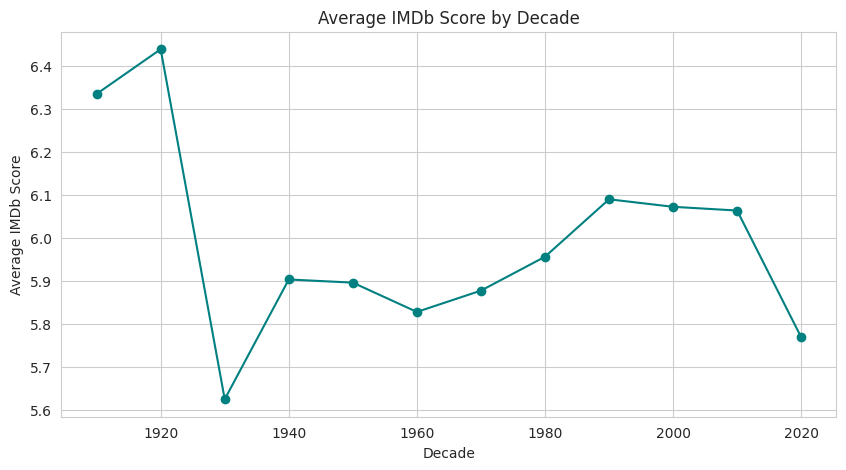

In [58]:
score_by_decade = df.groupby('decade')['imdb_score'].mean()
plt.figure(figsize=(10, 5))
plt.plot(score_by_decade.index, score_by_decade.values, marker='o', color='teal')
plt.title('Average IMDb Score by Decade')
plt.xlabel('Decade')
plt.ylabel('Average IMDb Score')
plt.show()

##### 1. Why did you pick the specific chart?

A line chart with markers shows how the average rating trends across decades, making it easy to spot whether newer content scores better or worse than older content.

##### 2. What is/are the insight(s) found from the chart?

Average IMDb scores are fairly stable across decades, hovering around 5.8-6.1. They peaked slightly in the 1990s (~6.1) and then dipped to the lowest value in the 2020s (~5.77) - the same period when the catalogue grew the fastest. Very old decades have few titles, so their averages are noisier.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive impact: quality has stayed broadly consistent over time, so the catalogue's average standard has not collapsed despite rapid expansion.

Possible negative impact: the dip in the 2020s suggests that the recent surge in volume may have come at the cost of *quality* - Prime appears to have added a lot of average/below-average new titles. This "quantity over quality" trend is a warning sign: it could lower viewer satisfaction even as the library grows.

#### Chart - 12 - IMDb Score vs TMDB Score (Bivariate: Numerical-Numerical)

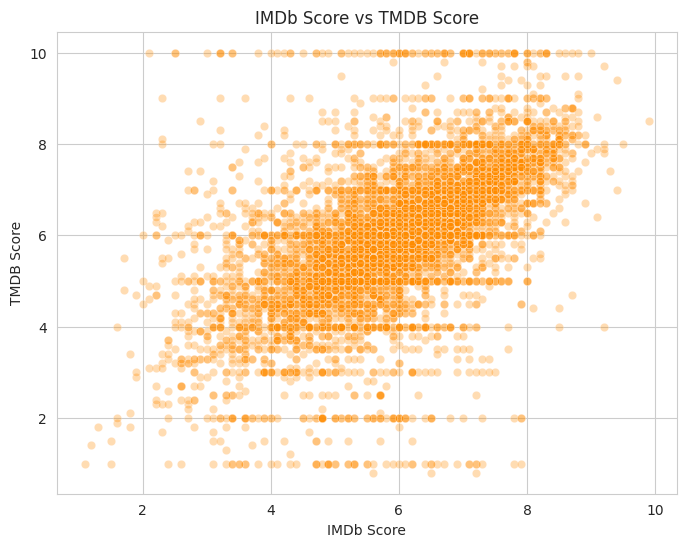

In [59]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x='imdb_score', y='tmdb_score', alpha=0.3, color='darkorange')
plt.title('IMDb Score vs TMDB Score')
plt.xlabel('IMDb Score')
plt.ylabel('TMDB Score')
plt.show()

##### 1. Why did you pick the specific chart?

A scatter plot compares the two independent rating systems title-by-title, showing whether IMDb and TMDB tend to agree on quality.

##### 2. What is/are the insight(s) found from the chart?

The two scores show a moderate positive relationship (correlation ~ 0.58) - they broadly agree, with points trending upward from bottom-left to top-right. However, the spread is wide: many titles get quite different scores on the two platforms, and TMDB scores cluster a bit higher overall.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive impact: because the two sources broadly agree, Prime can trust either rating as a reasonable quality signal, and can use TMDB to fill gaps where IMDb scores are missing.

Possible negative impact: the wide scatter means the two systems disagree on many individual titles, so relying on a single score for promotion or recommendations could misjudge a title. A combined/average rating would be safer than trusting one source alone.

#### Chart - 13 - Top Genres split by Content Type (Bivariate: Categorical-Categorical)

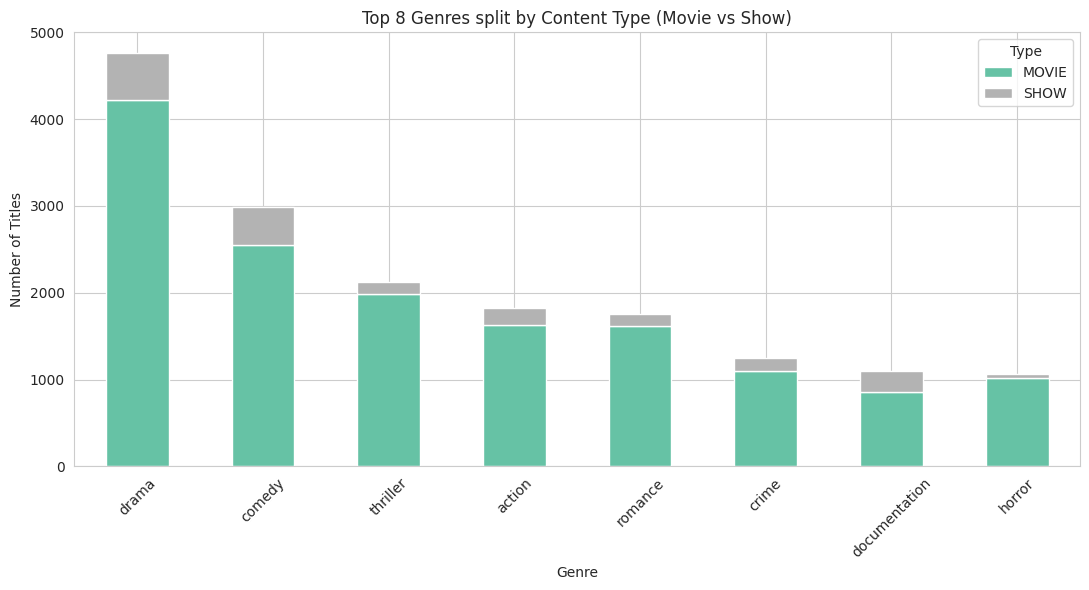

In [60]:
# crosstab needs a unique index, so reset it after exploding
exploded = df.explode('genres_list').reset_index(drop=True)
top_genres = exploded['genres_list'].value_counts().head(8).index
subset = exploded[exploded['genres_list'].isin(top_genres)]
genre_type = pd.crosstab(subset['genres_list'], subset['type']).loc[top_genres]
genre_type.plot(kind='bar', stacked=True, figsize=(11, 6), colormap='Set2')
plt.title('Top 8 Genres split by Content Type (Movie vs Show)')
plt.xlabel('Genre')
plt.ylabel('Number of Titles')
plt.xticks(rotation=45)
plt.legend(title='Type')
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A stacked bar chart is ideal for comparing two categorical variables at once: it shows the total titles per genre and, within each bar, the split between movies and shows.

##### 2. What is/are the insight(s) found from the chart?

Across every top genre, movies vastly outnumber shows - the movie segment dominates each bar. Drama and comedy are the largest genres for both formats. Shows make up only a thin slice everywhere, confirming that the movie-heavy imbalance holds *within* genres, not just overall.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive impact: Prime has broad genre coverage in movies, so film-focused viewers find depth in every major genre.

Possible negative impact: the near-absence of shows in popular genres like drama, thriller and action is a clear content gap. Since shows both retain viewers longer and score higher (Chart 8), the lack of genre-rich series is a missed opportunity - Prime could prioritise developing shows in its strongest genres.

#### Chart - 14 - Correlation Heatmap

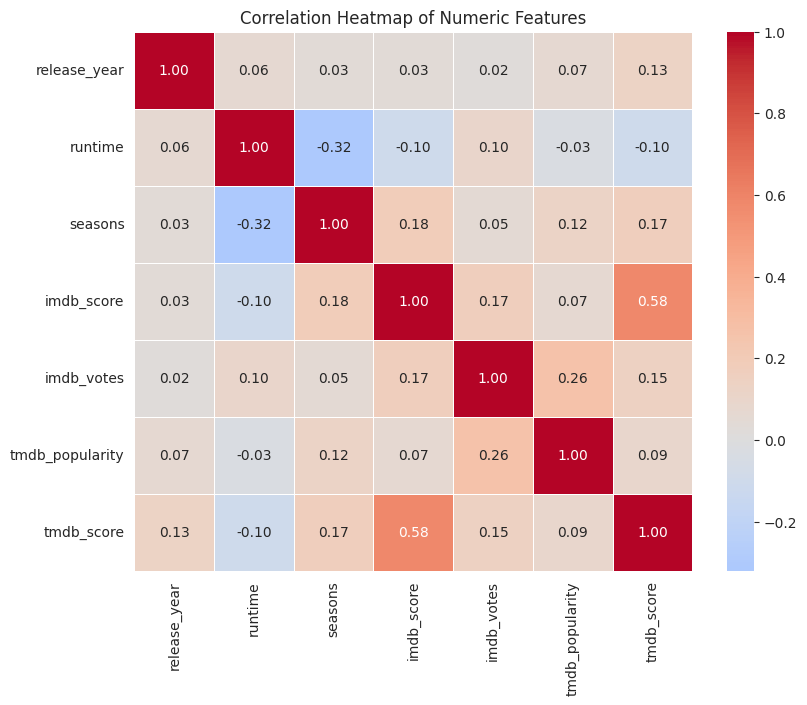

In [61]:
numeric_cols = ['release_year', 'runtime', 'seasons', 'imdb_score', 'imdb_votes', 'tmdb_popularity', 'tmdb_score']
corr = df[numeric_cols].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5, center=0)
plt.title('Correlation Heatmap of Numeric Features')
plt.show()

##### 1. Why did you pick the specific chart?

A correlation heatmap is the best way to view the relationships among *many* numeric variables at once. The colour and the annotated number in each cell instantly show which pairs are positively related, negatively related, or unrelated - a true multivariate summary.

##### 2. What is/are the insight(s) found from the chart?

The strongest relationship is between IMDb score and TMDB score (~ 0.58) - the two rating systems agree moderately. IMDb votes and TMDB popularity are mildly positive (~ 0.26), as both reflect audience attention. Most other pairs are weak: score vs votes ~ 0.17, and runtime vs score is slightly negative (~ −0.10), meaning longer titles are *not* better rated. Overall, the numeric features are largely independent, with rating-to-rating being the only meaningful link.

##### 3. Will the gained insights help creating a positive business impact?

Yes. Since IMDb and TMDB scores agree (~0.58), the platform can use either as a reliable quality filter when buying or promoting content. The weak link between popularity/votes and score is important for the marketing team: popular does not always mean good, so promotion budgets should not chase popularity alone. Runtime being slightly negative against score is a mild warning for investors that long titles are not automatically better value.

#### Chart - 15 - Pair Plot

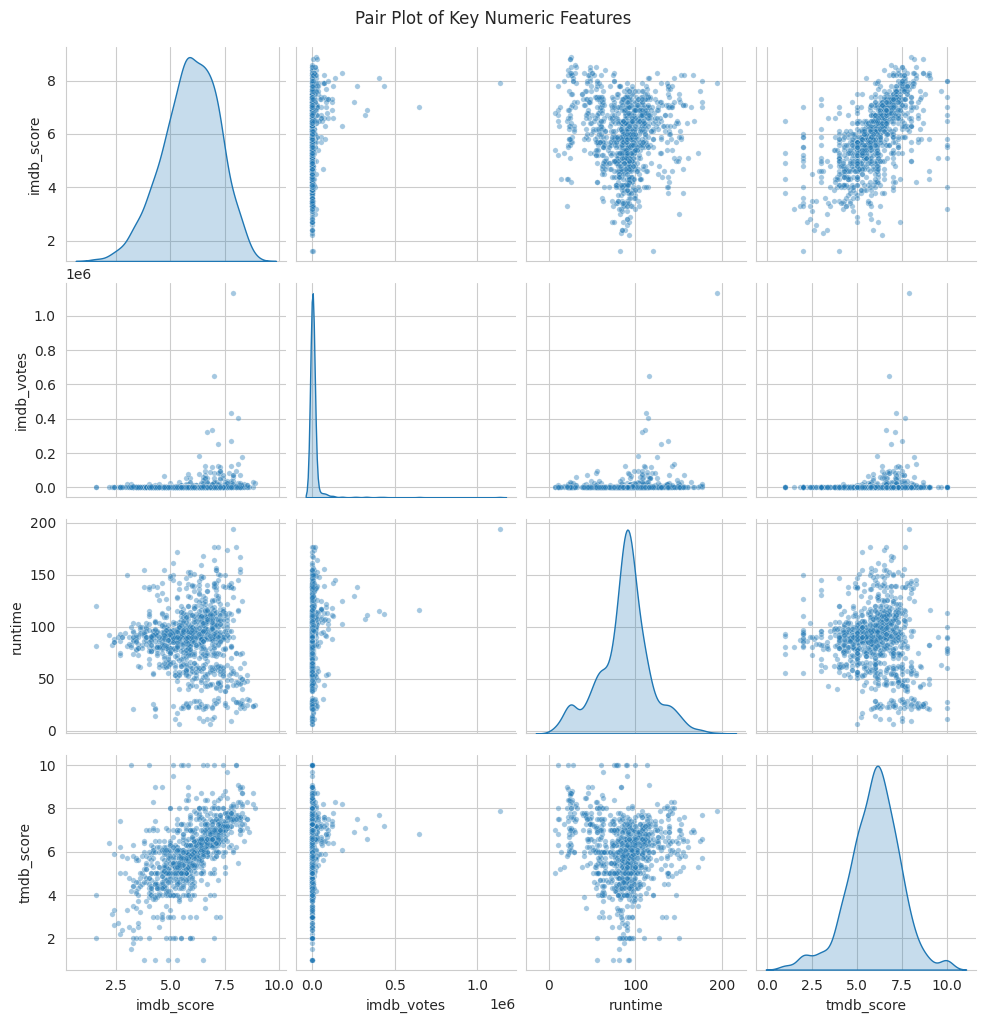

In [62]:
pair_cols = ['imdb_score', 'imdb_votes', 'runtime', 'tmdb_score']
pair_sample = df[pair_cols].dropna().sample(n=1000, random_state=42)
sns.pairplot(pair_sample, diag_kind='kde', plot_kws={'alpha': 0.4, 's': 15})
plt.suptitle('Pair Plot of Key Numeric Features', y=1.02)
plt.show()

##### 1. Why did you pick the specific chart?

A pair plot lets us inspect every pairwise relationship and every single-variable distribution in one figure. It is a quick multivariate scan that confirms (visually) the patterns the correlation heatmap summarised numerically.

##### 2. What is/are the insight(s) found from the chart?

The diagonals show that IMDb and TMDB scores are roughly bell-shaped around 6, while imdb_votes is heavily right-skewed (a few titles get huge vote counts). The clearest pairwise pattern is the upward imdb_score vs tmdb_score cloud (matching the 0.58 correlation). Runtime shows no clear relationship with any rating. This confirms ratings relate mainly to each other, not to length or vote count.

##### 3. Will the gained insights help creating a positive business impact?

Yes. The pair plot shows runtime has no link with ratings, so the content team does not need to push for shorter or longer titles to win on quality - they should focus on story and genre instead. The heavy skew in votes is a negative signal: audience attention is concentrated on a few blockbusters, so most of the catalogue gets very little engagement. Marketing (via recommendations and homepage placement) can spread attention to good but less-viewed titles.

#### Chart - 16 - Top 10 Actors by Number of Titles (Multivariate / credits.csv)

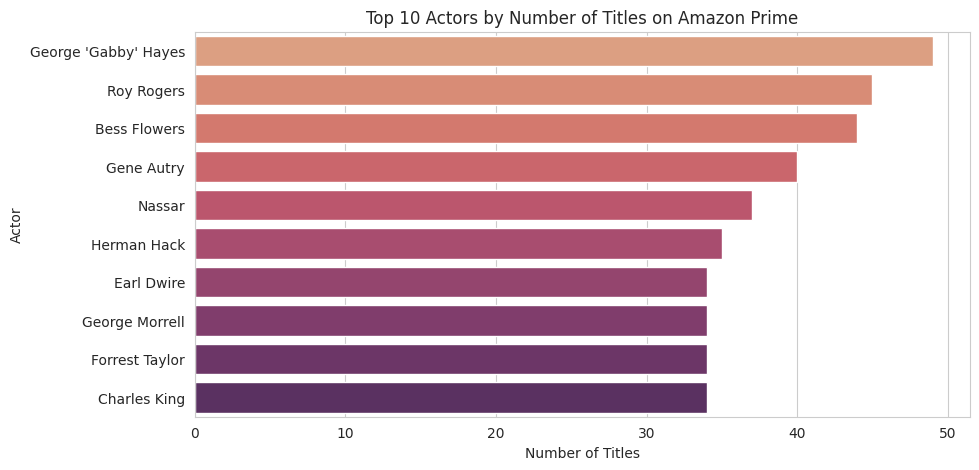

In [63]:
actor_counts = (credits_clean[credits_clean['role'] == 'ACTOR']
                .groupby('name')['id'].nunique()
                .sort_values(ascending=False).head(10))
plt.figure(figsize=(10, 5))
sns.barplot(x=actor_counts.values, y=actor_counts.index, hue=actor_counts.index, palette='flare', legend=False)
plt.title('Top 10 Actors by Number of Titles on Amazon Prime')
plt.xlabel('Number of Titles')
plt.ylabel('Actor')
plt.show()

##### 1. Why did you pick the specific chart?

A horizontal bar chart ranks the most frequent actors clearly. We use the credits table and count distinct titles per actor, which is the natural way to measure who appears most across the catalogue.

##### 2. What is/are the insight(s) found from the chart?

The most frequent actors are George 'Gabby' Hayes (49), Roy Rogers (45), Bess Flowers (44) and Gene Autry (40) - all classic mid-20th-century, largely Western-era American performers. This reflects how many old films sit in Prime's catalogue.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive impact: a deep library of classic films is a genuine niche strength and can attract nostalgia-driven and film-enthusiast subscribers.

Possible negative impact: none of the most-featured actors are contemporary stars, suggesting the catalogue skews toward older content with less mainstream pull today. Without recognisable modern names, Prime may struggle to attract younger audiences who follow current celebrities.

#### Chart - 17 - Top 10 Directors by Number of Titles (Multivariate / credits.csv)

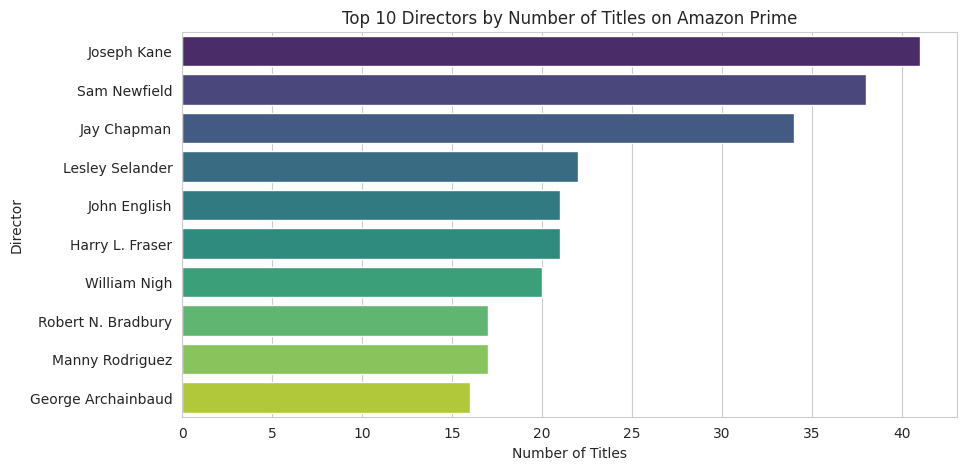

In [64]:
director_counts = (credits_clean[credits_clean['role'] == 'DIRECTOR']
                   .groupby('name')['id'].nunique()
                   .sort_values(ascending=False).head(10))
plt.figure(figsize=(10, 5))
sns.barplot(x=director_counts.values, y=director_counts.index, hue=director_counts.index, palette='viridis', legend=False)
plt.title('Top 10 Directors by Number of Titles on Amazon Prime')
plt.xlabel('Number of Titles')
plt.ylabel('Director')
plt.show()

##### 1. Why did you pick the specific chart?

Same logic as the actors chart: a ranked horizontal bar of distinct titles per director shows who is most prolific in the catalogue.

##### 2. What is/are the insight(s) found from the chart?

The most prolific directors are Joseph Kane (41), Sam Newfield (38) and Jay Chapman (34) - again largely classic-era filmmakers known for high-output studio and Western productions. This matches the actor finding: a large slice of the catalogue is older American cinema.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive impact: strong representation of prolific classic directors reinforces Prime's value as a deep film archive.

Possible negative impact: the absence of well-known modern directors among the top contributors again signals a tilt toward older content. For a platform competing on fresh, marquee titles, leaning on legacy filmmakers is a weakness that could limit buzz and new-subscriber appeal.

#### Chart - 18 - Average IMDb Score by Top Genres (Bivariate: Categorical-Numerical)

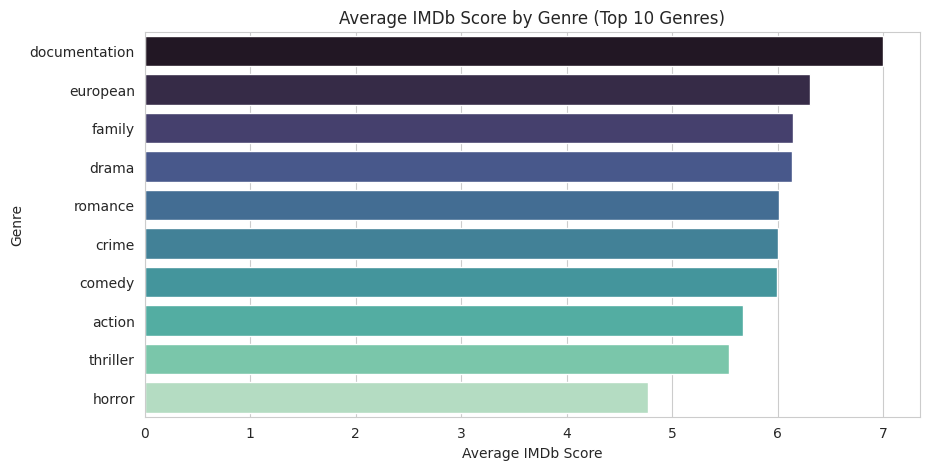

In [65]:
exploded_g = df.explode('genres_list').reset_index(drop=True)
top_g = exploded_g['genres_list'].value_counts().head(10).index
avg_score_genre = (exploded_g[exploded_g['genres_list'].isin(top_g)]
                   .groupby('genres_list')['imdb_score'].mean()
                   .sort_values(ascending=False))
plt.figure(figsize=(10, 5))
sns.barplot(x=avg_score_genre.values, y=avg_score_genre.index, hue=avg_score_genre.index, palette='mako', legend=False)
plt.title('Average IMDb Score by Genre (Top 10 Genres)')
plt.xlabel('Average IMDb Score')
plt.ylabel('Genre')
plt.show()

##### 1. Why did you pick the specific chart?

A horizontal bar chart of the average score per genre directly compares genre *quality* (not just quantity). It complements Chart 6, which showed genre volume.

##### 2. What is/are the insight(s) found from the chart?

Documentation is the highest-rated genre (~ 6.99), followed by european, family and drama (~ 6.1-6.3). At the bottom are horror (~ 4.77), thriller (~ 5.54) and action (~ 5.67). Strikingly, some of the *largest* genres by volume (thriller, action) are among the *lowest* rated.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive impact: documentaries, drama and family content score well, so promoting and expanding these can raise perceived catalogue quality and satisfy quality-seeking viewers.

Possible negative impact: Prime holds a large amount of horror, thriller and action content that is, on average, poorly rated. Continuing to stock low-quality titles in these high-volume genres can hurt viewer satisfaction and the platform's reputation, even though they add to the title count.

#### Chart - 19 - Movies vs Shows Released per Decade (Multivariate: Decade x Type)

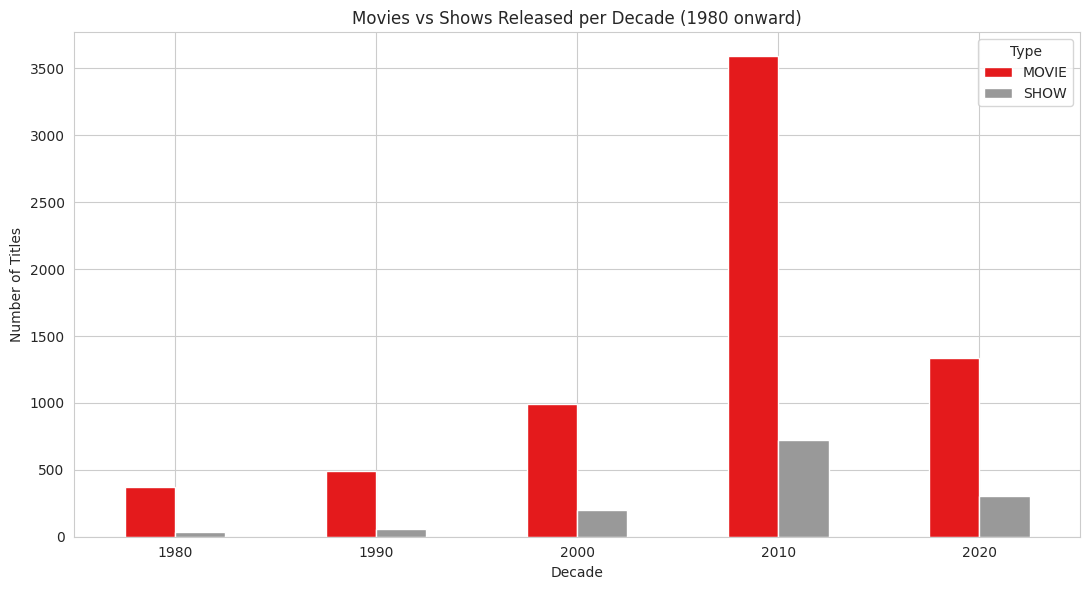

In [66]:
decade_type = df[df['decade'] >= 1980].groupby(['decade', 'type']).size().unstack(fill_value=0)
decade_type.plot(kind='bar', figsize=(11, 6), colormap='Set1')
plt.title('Movies vs Shows Released per Decade (1980 onward)')
plt.xlabel('Decade')
plt.ylabel('Number of Titles')
plt.xticks(rotation=0)
plt.legend(title='Type')
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A grouped bar chart shows two categorical dimensions (decade and type) against a count, making it easy to compare the growth of movies versus shows side by side over time.

##### 2. What is/are the insight(s) found from the chart?

Both formats grew sharply, peaking in the 2010s (~ 3,590 movies and 725 shows). Movies outnumber shows in every decade by roughly 4-5x. While shows did grow in absolute terms, their *share* of new content stayed small throughout.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive impact: the steady rise in both formats shows healthy catalogue expansion, and the growing absolute number of shows is a step in the right direction.

Possible negative impact: even at their peak, shows remained a small minority of additions. Given that shows score higher and aid retention, this persistent under-investment in series across every decade is a long-running strategic gap rather than a one-off.

#### Chart - 20 - Number of Seasons per TV Show (Univariate, shows only)

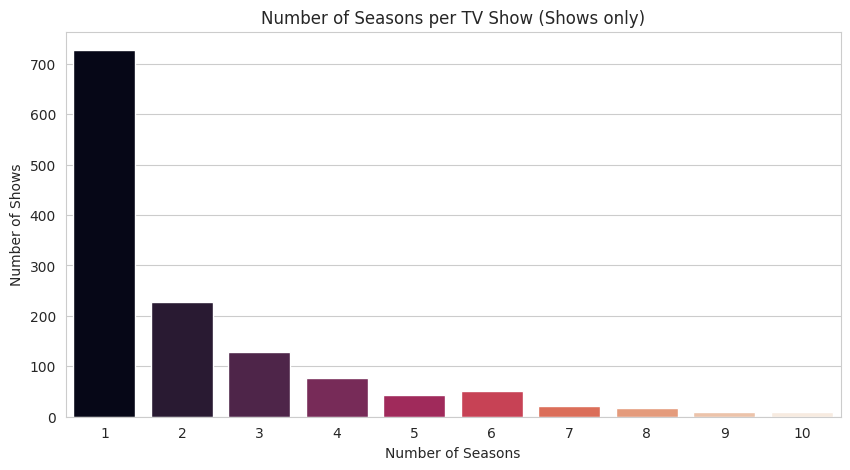

In [67]:
shows = df[df['type'] == 'SHOW']
season_counts = shows['seasons'].value_counts().sort_index().head(10)
plt.figure(figsize=(10, 5))
sns.barplot(x=season_counts.index.astype(int), y=season_counts.values, hue=season_counts.index, palette='rocket', legend=False)
plt.title('Number of Seasons per TV Show (Shows only)')
plt.xlabel('Number of Seasons')
plt.ylabel('Number of Shows')
plt.show()

##### 1. Why did you pick the specific chart?

A bar chart of season counts (a numeric but discrete variable) clearly shows how many shows are short-lived versus long-running, which a histogram would blur.

##### 2. What is/are the insight(s) found from the chart?

Most shows are very short-lived: about 727 of 1,357 shows (~ 54%) have only 1 season, and the median is 1 season (mean ~ 2.8). A small number of long-running shows stretch up to 51 seasons, creating a long tail.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive impact: the few long-running shows (many seasons) are valuable anchors that keep loyal viewers engaged for long stretches.

Possible negative impact: the majority being single-season suggests that few series are renewed or sustained. Short-lived shows give viewers little reason to stay subscribed long-term, which weakens retention - again pointing to a need for stronger, multi-season original series.

## *Statistical Analysis - Testing the Hypotheses*

The charts *suggest* patterns, but a visual gap can happen by chance. Here I check the three hypotheses listed at the start with simple statistical tests.

I use **non-parametric tests** (Mann-Whitney U, Spearman, Kruskal-Wallis) because the IMDb score and votes columns are skewed and not perfectly normal - these tests compare ranks instead of assuming a bell curve. Significance level used: **alpha = 0.05** (if p-value < 0.05, the difference is unlikely to be due to chance).

In [68]:
from scipy import stats

ALPHA = 0.05

def report(test_name, stat, p_value):
    # small helper so every test prints its result in the same format
    verdict = 'Reject H0 (significant)' if p_value < ALPHA else 'Fail to reject H0 (not significant)'
    print(f'{test_name}\n  statistic = {stat:,.3f} | p-value = {p_value:.2e} -> {verdict}\n')

# Hypothesis 1: TV shows are rated higher than movies on IMDb
movie_scores = df.loc[df['type'] == 'MOVIE', 'imdb_score'].dropna()
show_scores = df.loc[df['type'] == 'SHOW', 'imdb_score'].dropna()
print(f'Median IMDb - Movies: {movie_scores.median():.2f} | Shows: {show_scores.median():.2f}')
u_stat, p_val = stats.mannwhitneyu(show_scores, movie_scores, alternative='greater')
report('H1 - Mann-Whitney U (shows > movies)', u_stat, p_val)

# Hypothesis 2: IMDb score and TMDB score move together
both = df[['imdb_score', 'tmdb_score']].dropna()
rho, p_val = stats.spearmanr(both['imdb_score'], both['tmdb_score'])
report('H2 - Spearman correlation (IMDb vs TMDB)', rho, p_val)

# Hypothesis 3: average IMDb score differs across the top 5 main genres
top5 = df['main_genre'].value_counts().head(5).index
groups = [df.loc[df['main_genre'] == g, 'imdb_score'].dropna() for g in top5]
h_stat, p_val = stats.kruskal(*groups)
print('Genres tested:', list(top5))
report('H3 - Kruskal-Wallis (IMDb score across genres)', h_stat, p_val)

Median IMDb - Movies: 5.90 | Shows: 7.30
H1 - Mann-Whitney U (shows > movies)
  statistic = 7,089,738.500 | p-value = 4.74e-227 -> Reject H0 (significant)

H2 - Spearman correlation (IMDb vs TMDB)
  statistic = 0.645 | p-value = 0.00e+00 -> Reject H0 (significant)

Genres tested: ['drama', 'comedy', 'thriller', 'documentation', 'horror']
H3 - Kruskal-Wallis (IMDb score across genres)
  statistic = 1,307.782 | p-value = 6.84e-282 -> Reject H0 (significant)



##### What did the tests tell us?

- **H1 (shows vs movies):** the p-value is far below 0.05, so the higher rating of TV shows is statistically significant, not a coincidence. This backs the recommendation to invest more in series.
- **H2 (IMDb vs TMDB):** a positive Spearman correlation with a tiny p-value confirms the two rating platforms agree - so either one can be used as a quality signal.
- **H3 (genres):** the Kruskal-Wallis test shows genre has a significant effect on rating, which means genre-level decisions (promote documentary/drama, improve horror/thriller curation) are backed by data and not just by eyeballing a bar chart.

## 5. Solution to Business Objective

#### What do you suggest the client to achieve Business Objective ?
Explain Briefly.

Based on the analysis, here is what Amazon Prime Video should do to achieve its business objective:

1. Invest more in TV shows. Shows are rated far higher than movies (~ 7.1 vs 5.8) and drive long-term bingeing and retention, yet they are only ~14% of the catalogue and 54% of them have a single season. Commissioning more multi-season original series is the single biggest opportunity.
2. Prioritise quality over quantity. The average rating dipped in the 2020s - the period of fastest growth - suggesting many recently added titles are below average. Tighter curation and acquisition of high-rated content would protect the platform's reputation.
3. Lean into high-rated genres and fix weak ones. Documentary, drama and family score best on average, while the high-volume horror, thriller and action genres score lowest. Promote and expand the strong genres, and curate/upgrade quality in the weak-but-popular ones.
4. Expand regional content. Production is heavily US-centric; India already ranks #2. Growing local-language libraries (India and beyond) can unlock fast-growing international markets.
5. Add certifications and family content. Two-thirds of titles are unrated and family-rated content is thin. Adding certifications improves parental filtering and trust, and more family content captures a loyal household segment.
6. Improve discovery. Score and popularity are only weakly linked, so many highly-rated low-vote "hidden gems" go unnoticed - better recommendations can lift engagement with content Prime already owns.
7. Refresh with modern talent. The most-featured actors and directors are classic-era names; adding recognisable contemporary stars would broaden mainstream and younger-audience appeal.

# Conclusion

This Exploratory Data Analysis of the Amazon Prime Video catalogue (9,871 titles and 124,235 cast/crew records) turned raw data into clear, business-relevant insights.

Key findings:
- The catalogue is movie-dominated (~86% movies, ~14% shows) and has grown sharply since ~2010, peaking around 2021.
- TV shows are rated noticeably higher than movies (~ 7.1 vs 5.8), yet remain a small minority - and ~54% of shows last only one season.
- Drama and comedy dominate by volume, but documentaries, drama and family score highest on quality while horror, thriller and action score lowest.
- Production is concentrated in the United States, with India a strong second.
- IMDb scores centre around 6.0; ratings relate mainly to each other (IMDb vs TMDB ~ 0.58) and only weakly to popularity or runtime.

Most important insight: Prime's catalogue competes on *volume of average-rated movies*, while its higher-quality, higher-retention asset - TV shows - is under-developed. Rebalancing toward more (and longer-running) shows, in its strongest genres and growing regions, is the clearest path to higher satisfaction and retention.

What I learned: how to clean a real, messy dataset (handling structural vs true missing values, parsing list-like text, removing duplicates), how to choose the right chart for each variable pairing using the UBM framework, and how to translate visual patterns into stakeholder recommendations.

Future improvements: text analysis of descriptions, a predictive model for ratings/popularity, and an interactive dashboard for live catalogue monitoring.

### *Hurrah! You have successfully completed your EDA Capstone Project !!!*